# Onze Prime · Três Grandes lab

Goal: reach the record XI (shown as **90,5** on the ranking).

1. **Map** every player per position (from the site's own data bundle).
2. **Ceiling**: the best possible XI per formation, and what "90,5" really is.
3. **Tests**: the Python engine against the real site engine.
4. **Simulate** policies over thousands of games.
5. **Hunt** for the record XI offline.
6. **Live** play in the browser with Playwright (off by default).

In [1]:
import sys, subprocess
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from onzeprime import data, engine, optimizer as opt, simulate as sim, strategies as st

pd.set_option("display.width", 160)
clubs, by_club = data.load()          # downloads + caches the bundle once (data/onzeprime_bundle.js)
pool = opt.pool_for_mode(by_club, "grandes")
print(f"{sum(map(len, by_club.values()))} player-seasons in 24 clubs · Três Grandes pool: {len(pool)} "
      f"({len({p.id for p in pool})} distinct people)")

807 player-seasons in 24 clubs · Três Grandes pool: 263 (256 distinct people)


## 1 · Player map per position (Três Grandes)

In [2]:
df = data.players_dataframe(clubs_filter=data.GRANDES)
order = ["GR", "DD", "DC", "DE", "MDC", "MC", "MO", "ED", "EE", "PL"]
counts = pd.crosstab(df.pos_main, df.clube_nome).reindex(order)
counts["total"] = counts.sum(axis=1)
counts["ovr ≥ 88"] = df[df.ovr >= 88].groupby("pos_main").size().reindex(order).fillna(0).astype(int)
counts

clube_nome,Benfica,FC Porto,Sporting,total,ovr ≥ 88
pos_main,,,,,
GR,9,5,5,19,2
DD,7,9,6,22,0
DC,12,16,13,41,1
DE,7,6,7,20,0
MDC,7,7,7,21,1
MC,14,12,9,35,4
MO,5,7,6,18,4
ED,4,7,11,22,3
EE,7,7,7,21,5


In [3]:
# Top 5 per main position: the players the bot should aim for
top = (df.sort_values("ovr", ascending=False).groupby("pos_main").head(5)
         .sort_values(["pos_main", "ovr"], ascending=[True, False]))
top.assign(pos_main=pd.Categorical(top.pos_main, order, ordered=True)).sort_values(["pos_main", "ovr"], ascending=[True, False])[
    ["pos_main", "nome", "clube_nome", "epoca", "ovr", "pos"]].reset_index(drop=True)

,pos_main,nome,clube_nome,epoca,ovr,pos
0,GR,Diogo Costa,FC Porto,2022/23,88,GR
1,GR,Vítor Baía,FC Porto,2003/04,88,GR
2,GR,Ederson,Benfica,2016/17,86,GR
3,GR,Rui Patrício,Sporting,2015/16,86,GR
4,GR,Helton,FC Porto,2010/11,85,GR
5,DD,Pedro Porro,Sporting,2021/22,86,DD
6,DD,Paulo Ferreira,FC Porto,2003/04,85,DD
7,DD,Bosingwa,FC Porto,2007/08,85,DD
8,DD,Danilo,FC Porto,2014/15,85,DD
9,DD,Maxi Pereira,Benfica,2012/13,85,DD


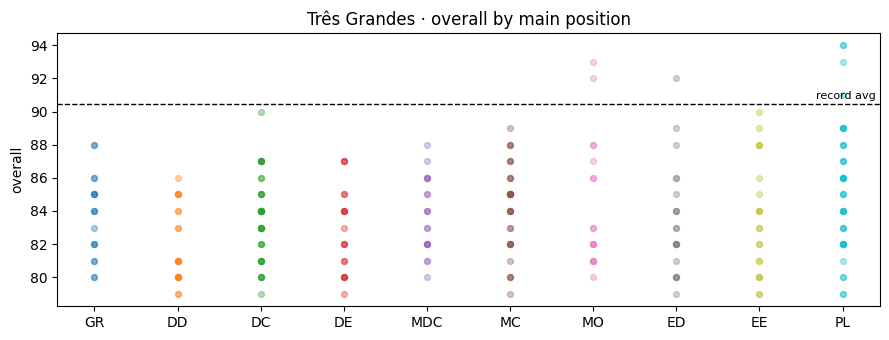

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for pos in order:
    ax.scatter([pos] * (df.pos_main == pos).sum(), df.loc[df.pos_main == pos, "ovr"], alpha=.35, s=18)
ax.axhline(995 / 11, ls="--", lw=1, color="k"); ax.text(9.4, 995 / 11 + .3, "record avg", ha="right", fontsize=8)
ax.set_ylabel("overall"); ax.set_title("Três Grandes · overall by main position"); plt.tight_layout()

## 2 · Theoretical ceiling per formation

Exact best XI via linear assignment (slots × people; each person used once, multi-position players allowed).
The site displays `avg.toFixed(1)`, so **995 / 11 = 90.4545 is shown as "90,5"**. The current record is the perfect XI.

In [5]:
ceil = pd.DataFrame([{"formation": r["formation"], "sum": round(r["avg"] * 11), "avg": r["avg"], "shown": f'{r["avg"]:.1f}'}
                     for r in opt.best_xi_all(pool)])
ceil

,formation,sum,avg,shown
0,4-4-2,995,90.454545,90.5
1,4-2-4,995,90.454545,90.5
2,3-5-2,995,90.454545,90.5
3,3-4-3,991,90.090909,90.1
4,4-2-3-1,990,90.000000,90.0
5,4-3-3,989,89.909091,89.9
6,5-3-2,988,89.818182,89.8
7,5-4-1,988,89.818182,89.8


In [6]:
best = opt.best_xi(pool, "3-5-2")
pd.DataFrame(best["lineup"])[["slot", "nome", "clube", "epoca", "ovr"]]

,slot,nome,clube,epoca,ovr
0,PL1,Gyökeres,scp,2024/25,94
1,PL2,Mário Jardel,scp,2001/02,94
2,AE,Luis Díaz,fcp,2021/22,90
3,MC1,Deco,fcp,2003/04,93
4,MC2,Bruno Fernandes,scp,2018/19,92
5,AD,Hulk,fcp,2011/12,92
6,MDC,Matić,slb,2012/13,88
7,DC1,Ricardo Carvalho,fcp,2003/04,90
8,DC2,Bruno Alves,fcp,2008/09,87
9,DC3,Coates,scp,2020/21,87


In [7]:
# Per role, the elite candidates in 3-5-2 (what the "elite" policy uses as its bar)
{role: [(p.nome, p.clube, p.ovr) for p in ps] for role, ps in opt.role_table(pool, "3-5-2", top=4).items()}

{'PL': [('Mário Jardel', 'scp', 94),
  ('Gyökeres', 'scp', 94),
  ('Falcao', 'fcp', 93),
  ('Hulk', 'fcp', 92)],
 'AE': [('Luis Díaz', 'fcp', 90),
  ('Simão', 'slb', 89),
  ('Quaresma', 'fcp', 89),
  ('Di María', 'slb', 88)],
 'MC': [('Deco', 'fcp', 93),
  ('Bruno Fernandes', 'scp', 92),
  ('Lucho González', 'fcp', 89),
  ('Enzo Fernández', 'slb', 88)],
 'AD': [('Hulk', 'fcp', 92),
  ('Simão', 'slb', 89),
  ('Quaresma', 'fcp', 89),
  ('Di María', 'slb', 88)],
 'MDC': [('Matić', 'slb', 88),
  ('Hjulmand', 'scp', 87),
  ('Witsel', 'slb', 86),
  ('João Neves', 'slb', 86)],
 'DC': [('Ricardo Carvalho', 'fcp', 90),
  ('Luisão', 'slb', 87),
  ('David Luiz', 'slb', 87),
  ('Garay', 'slb', 87)],
 'GR': [('Vítor Baía', 'fcp', 88),
  ('Diogo Costa', 'fcp', 88),
  ('Ederson', 'slb', 86),
  ('Rui Patrício', 'scp', 86)]}

## 3 · Tests

`tests/test_parity_js.py` loads the site's real `core.js` into a blank headless Chromium page (no network) and checks the
Python port gives **identical draws** (club + 6 options every round, including swaps) for many seeds and formations.

In [8]:
r = subprocess.run([sys.executable, "-m", "pytest", "-q", str(ROOT / "tests")], capture_output=True, text=True, cwd=ROOT)
print(r.stdout[-1500:] or r.stderr[-1500:])
assert r.returncode == 0

..............................                                           [100%]
30 passed in 6.65s



In [9]:
# Inline checks
g = engine.Game(clubs, by_club, "grandes", "3-5-2", seed=2026)
assert len(g.draw.options) == 6 and g.draw.club in data.GRANDES
assert g.swap() and g.swap() and not g.swap()
done = sim.play(clubs, by_club, st.GreedyPolicy(), "3-5-2", seed=2026)
assert done.finished and len({p.id for p in done.xi.values()}) == 11
assert engine.replay(clubs, by_club, "grandes", "3-5-2", 2026, done.actions).lineup() == done.lineup()
print("inline checks ok ·", f"{done.average():.2f}", done.lineup()[:3], "...")

inline checks ok · 87.91 [('PL1', 'Hulk', 'fcp', 92), ('PL2', 'Cardozo', 'slb', 89), ('AE', 'Gaitán', 'slb', 88)] ...


## 4 · Policy comparison (same seeds for every policy)

In [10]:
N, F = 800, "3-5-2"
policies = {
    "greedy": st.GreedyPolicy(),
    "elite k=3": st.EliteTargetPolicy(pool, F, k=3, swap_below=-3),
    "ceiling margin=2": st.CeilingPolicy(pool, F, swap_margin=2),
    "ceiling target=995": st.CeilingPolicy(pool, F, target_sum=995),
}
runs = {name: sim.run_many(clubs, by_club, p, F, n=N, seed_start=50_000) for name, p in policies.items()}
pd.DataFrame({k: sim.summarize(v) for k, v in runs.items()}).T.round(3)

,games,mean,p50,p95,max,P(record),P(>=990)
greedy,800.0,87.840,87.818,88.732,89.454,0.0,0.000
elite k=3,800.0,88.629,88.636,89.454,90.182,0.0,0.004
ceiling margin=2,800.0,88.560,88.636,89.546,90.273,0.0,0.006
ceiling target=995,800.0,88.428,88.454,89.364,90.364,0.0,0.004


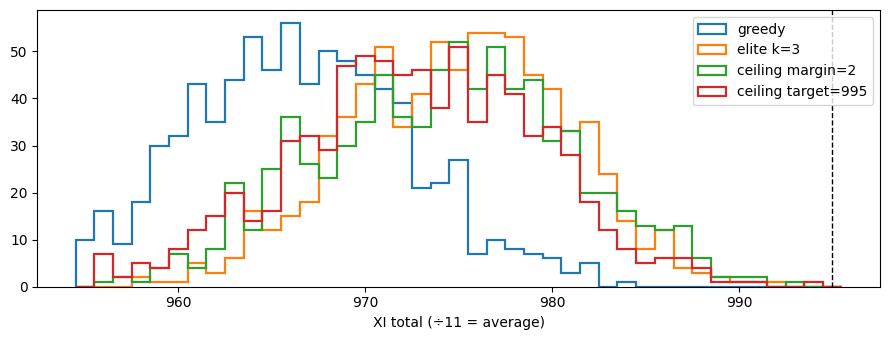

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.5))
bins = np.arange(955, 997) - .5
for name, d in runs.items():
    ax.hist(d["sum"], bins=bins, histtype="step", lw=1.6, label=name)
ax.axvline(995, color="k", ls="--", lw=1); ax.set_xlabel("XI total (÷11 = average)"); ax.legend(); plt.tight_layout()

### Small grid search: `elite` policy parameters

In [12]:
grid = sim.grid_search(clubs, by_club, lambda **kw: st.EliteTargetPolicy(pool, F, **kw), F,
                       grid={"k": [1, 3], "swap_below": [-5, -3, -1]}, n=300)
grid.round(3)

,k,swap_below,games,mean,p50,p95,max,P(record),P(>=990),secs
0,3,-3,300.0,88.597,88.636,89.364,90.000,0.0,0.003,4.6
1,1,-3,300.0,88.571,88.636,89.368,90.091,0.0,0.007,4.8
2,3,-1,300.0,88.558,88.546,89.550,90.182,0.0,0.013,5.1
3,1,-1,300.0,88.508,88.454,89.636,90.273,0.0,0.023,5.1
4,1,-5,300.0,88.397,88.364,89.273,90.091,0.0,0.007,4.3
5,3,-5,300.0,88.365,88.364,89.182,89.818,0.0,0.000,4.2


## 5 · Record hunt (offline)

Run seeds in parallel until a game reaches 995. A full 20k-game hunt takes about 1–2 min on 7 cores.

In [13]:
hunt = sim.hunt("3-5-2", "ceiling", {"target_sum": 995}, n_games=20_000, seed_start=0, workers=7, stop_on_hit=False)
res = hunt["results"]
print(f'{hunt["games_played"]} games in {hunt["secs"]}s · best {hunt["best_sum"]} ({hunt["best_avg"]:.4f} → shown '
      f'{hunt["best_avg"]:.1f}) at seed {hunt["best_seed"]}')
print(f'P(record) ≈ {(res["sum"] >= 995).mean():.5f}  → about 1 in {1 / max((res["sum"] >= 995).mean(), 1e-9):,.0f} games')
res["sum"].value_counts().sort_index(ascending=False).head(8)

20000 games in 88.6s · best 995 (90.4545 → shown 90.5) at seed 7835
P(record) ≈ 0.00020  → about 1 in 5,000 games


sum
995     4
994     4
993     9
992     9
991    18
990    39
989    67
988    83
Name: count, dtype: int64

In [14]:
# The record game, and its replay through the engine (same check the site's server does for the ranking)
rep = engine.replay(clubs, by_club, "grandes", "3-5-2", hunt["best_seed"], hunt["actions"])
assert rep is not None and rep.lineup() == hunt["lineup"]
pd.DataFrame(hunt["lineup"], columns=["slot", "nome", "clube", "ovr"])

,slot,nome,clube,ovr
0,PL1,Mário Jardel,scp,94
1,PL2,Gyökeres,scp,94
2,AE,Luis Díaz,fcp,90
3,MC1,Bruno Fernandes,scp,92
4,MC2,Deco,fcp,93
5,AD,Hulk,fcp,92
6,MDC,Matić,slb,88
7,DC1,David Luiz,slb,87
8,DC2,Coates,scp,87
9,DC3,Ricardo Carvalho,fcp,90


## 6 · Live play (real browser)

Uses `onzeprime.live_bot.LiveBot`. It blocks the counter, ranking and analytics endpoints, so these games stay out of the
public counter and ranking. Kept small on purpose: the volume lives in the simulator above.
Set `RUN_LIVE = True` to play.

In [15]:
RUN_LIVE = False
if RUN_LIVE:
    from onzeprime.live_bot import LiveBot
    with LiveBot(formation="3-5-2", policy_name="hunter") as bot:
        print(bot.hunt(max_attempts=50, max_minutes=3))
    display(pd.DataFrame(bot.log).tail())